In [4]:
!pip install peft -q

تدريب مودل التوليد

In [1]:
import os
import subprocess
import shutil
import sys

# 1. تحديد المسارات
current_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
base_dir = os.path.abspath(os.path.join(current_dir, "..")) if "notebooks" in current_dir else current_dir

dataset_dir = os.path.join(base_dir, "dataset", "raw")
concept_dir = os.path.join(base_dir, "dataset", "3_mycustomboy")
output_dir = os.path.join(base_dir, "models", "lora")

train_script = os.path.join(base_dir, "sd-scripts", "sdxl_train_network.py")
model_path = os.path.join(base_dir, "models", "base", "animagine-xl-3.1.safetensors")

# نقل الصور ونظافة المجلدات
os.makedirs(concept_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

if os.path.exists(dataset_dir):
    for file in os.listdir(dataset_dir):
        src = os.path.join(dataset_dir, file)
        dst = os.path.join(concept_dir, file)
        if os.path.isfile(src):
            shutil.copy(src, dst)
    shutil.rmtree(dataset_dir, ignore_errors=True)

# 2. أمر التدريب الخفيف والسريع بدقة 768x768
train_command = [
    sys.executable,
    train_script,
    f'--pretrained_model_name_or_path={model_path}',
    f'--train_data_dir={os.path.join(base_dir, "dataset")}',
    f'--output_dir={output_dir}',
    '--output_name=my_anime_character_lora',
    '--save_model_as=safetensors',
    '--resolution=768,768',             # تخفيض الدقة لفك اختناق VRAM وسرعة فائقة
    '--train_batch_size=1',
    '--max_train_epochs=6',
    '--save_every_n_epochs=2',
    '--mixed_precision=fp16',
    '--save_precision=fp16',
    '--network_module=networks.lora',
    '--network_dim=16',
    '--network_alpha=8',
    '--learning_rate=1e-4',
    '--unet_lr=1e-4',
    '--text_encoder_lr=5e-5',
    '--optimizer_type=AdamW8bit',
    '--lr_scheduler=cosine',
    '--cache_latents',
    '--cache_latents_to_disk',
    '--sdpa',
    '--persistent_data_loader_workers',
    '--max_data_loader_n_workers=2'
]

print("\n...بدء التدريب الخفيف والسريع جدًا...\n")

process = subprocess.Popen(
    train_command,
    cwd=base_dir,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in iter(process.stdout.readline, ''):
    print(line, end='', flush=True)

process.stdout.close()
return_code = process.wait()

if return_code == 0:
    print("\n\nاكتمل التدريب بنجاح! تم حفظ ملف الـ LoRA في models/lora.")
else:
    print(f"\n\nحدث خطأ أثناء التدريب (كود الخروج: {return_code}).")


...بدء التدريب الخفيف والسريع جدًا...

2026-09-18 09:54:27 INFO     Using DreamBooth method.      train_network.py:937
                    INFO     prepare images.          dreambooth_dataset.py:274
                    INFO     get image size from name dreambooth_dataset.py:149
                             of cache files                                    

100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 15/15 [00:00<?, ?it/s]
                    INFO     set image size from      dreambooth_dataset.py:179
                             cache files: 15/15                                
                    INFO     found directory          dreambooth_dataset.py:221
                             c:\Users\OrbaTechs\Docum                          
                             ents\Visual_Studio_18\ca                          
                             rtoon-generator\dataset\                          
                             3_mycustomboy contains                            
                   

اختبار مودل التوليد

... جاري تحميل النموذج وتخفيف استخدام VRAM ...


Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (79 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['sharp focus']


... جاري توليد الصورة الآن ...


Token indices sequence length is longer than the specified maximum sequence length for this model (79 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['sharp focus']


  0%|          | 0/28 [00:00<?, ?it/s]

تم حفظ الصورة بنجاح في: c:\Users\OrbaTechs\Documents\Visual_Studio_18\cartoon-generator\test_output.png


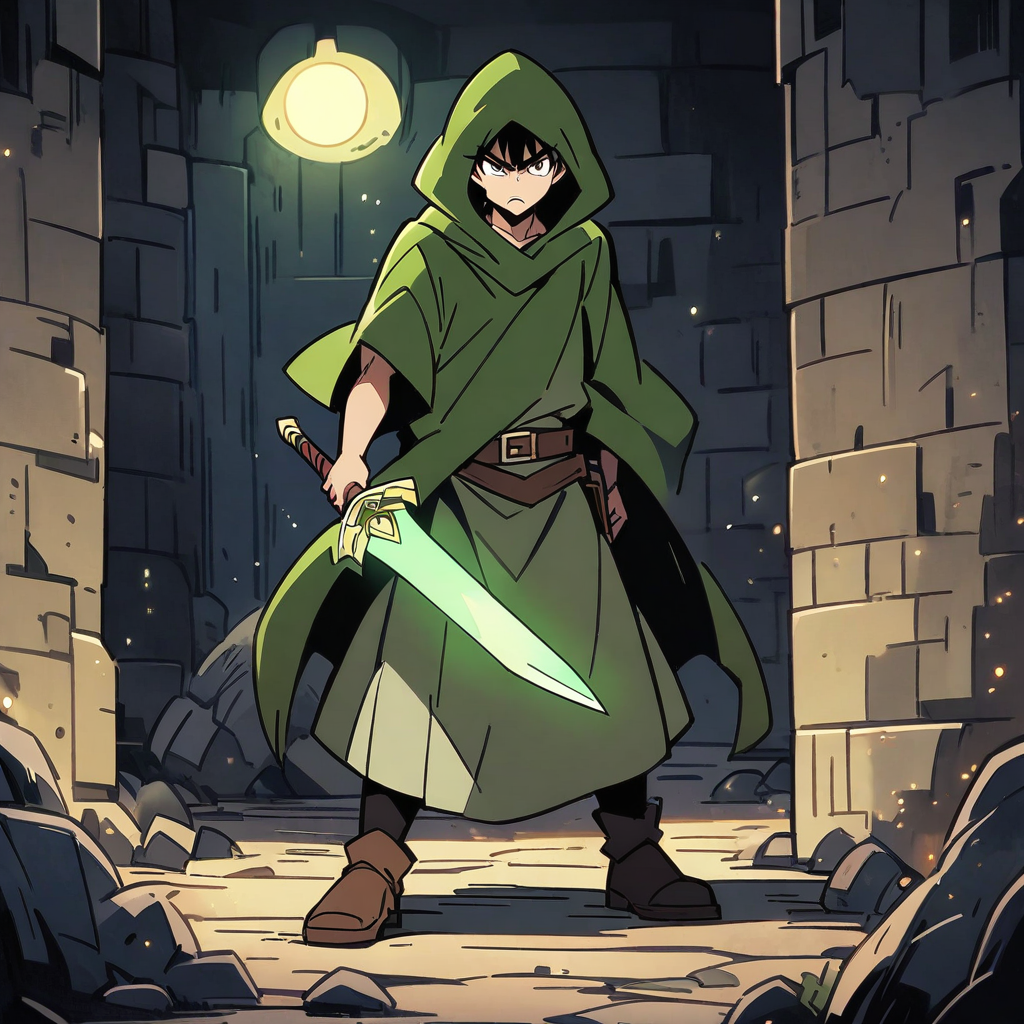

In [1]:
import torch
import gc
from diffusers import StableDiffusionXLPipeline
from diffusers.utils.logging import disable_progress_bar
import os

disable_progress_bar()

# تنظيف الذاكرة المؤقتة للـ GPU
gc.collect()
torch.cuda.empty_cache()

# 1. تحديد المسارات
current_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
base_dir = os.path.abspath(os.path.join(current_dir, "..")) if "notebooks" in current_dir else current_dir

model_path = os.path.join(base_dir, "models", "base", "animagine-xl-3.1.safetensors")
lora_dir = os.path.join(base_dir, "models", "lora")
lora_file = "my_anime_character_lora.safetensors"

print("... جاري تحميل النموذج وتخفيف استخدام VRAM ...")

# 2. تحميل النموذج
pipe = StableDiffusionXLPipeline.from_single_file(
    model_path,
    torch_dtype=torch.float16,
    use_safetensors=True
)

# 3. دمج الـ LoRA
pipe.load_lora_weights(lora_dir, weight_name=lora_file)

# 4. إدارة الذاكرة بذكاء لمنع OOM على 8GB VRAM
pipe.enable_model_cpu_offload()

# 5. الوصف (Prompt)
prompt = "masterpiece, best quality, anime style, 1boy, mycustomboy, dark fantasy, full body, mid shot, wearing a green hooded adventurer cloak, green tunic, leather belts, standing in an underground stone dungeon, stone floor, holding a glowing magical sword, looking directly at viewer with intense expression, dungeon entrance in background, magical particles, detailed equipment, dramatic lighting, sharp focus"
negative_prompt = "lowres, bad anatomy, bad hands, text, error, missing fingers, extra digit, fewer digits, cropped, worst quality, low quality, normal quality, jpeg artifacts, signature, watermark, username, blurry, smile, peaceful"

print("... جاري توليد الصورة الآن ...")

# 6. التوليد
image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=28,
    guidance_scale=7.0,
    width=1024,
    height=1024
).images[0]

# 7. الحفظ والعرض
output_image_path = os.path.join(base_dir, "test_output.png")
image.save(output_image_path)
print(f"تم حفظ الصورة بنجاح في: {output_image_path}")

display(image)